<a href="https://colab.research.google.com/github/ShouryaBatra/fbla-data-analysis/blob/main/charts3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

font_path = "/content/Raleway-Regular.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = "Raleway"

In [3]:
TEXT = "#1B1B1B"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D0D0D0",
    "axes.labelcolor": TEXT,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "text.color": TEXT,
    "font.size": 13,
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 14,
})

In [4]:
athletes = pd.read_csv("athlete_events.csv")
nocs = pd.read_csv("noc_regions.csv")

df = athletes.merge(nocs, on="NOC", how="left")
df = df[df["Season"] == "Summer"].copy()
df = df.rename(columns={"region": "Country"})

df["Medal_Won"] = df["Medal"].notna().astype(int)

In [5]:
medals_by_country_sport = (
    df[df["Medal_Won"] == 1]
    .groupby(["Country", "Sport"])["Medal_Won"]
    .sum()
    .reset_index(name="Medals_Won")
)

total_medals_by_country = (
    medals_by_country_sport
    .groupby("Country")["Medals_Won"]
    .sum()
    .reset_index(name="Total_Medals")
)

country_sport_share = medals_by_country_sport.merge(total_medals_by_country, on="Country", how="left")
country_sport_share["Share"] = country_sport_share["Medals_Won"] / country_sport_share["Total_Medals"]

country_sport_matrix = country_sport_share.pivot_table(
    index="Country",
    columns="Sport",
    values="Share",
    fill_value=0
)

country_sport_matrix.shape

(134, 52)

In [6]:
MIN_TOTAL_MEDALS = 20  # tweak: 10, 20, 50

valid_countries = total_medals_by_country.query("Total_Medals >= @MIN_TOTAL_MEDALS")["Country"]
X = country_sport_matrix.loc[valid_countries].copy()

X.shape

(70, 52)

In [7]:
k = 2
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

clustered = X.copy()
clustered["Cluster"] = clusters

# "Effective sports" metric: lower = more specialized, higher = more diverse
shares_only = clustered.drop(columns=["Cluster"])
effective_sports = 1 / (shares_only.pow(2).sum(axis=1))
clustered["Effective_Sports"] = effective_sports

cluster_summary = clustered.groupby("Cluster")["Effective_Sports"].mean().sort_values()

specialist_cluster = cluster_summary.index[0]
generalist_cluster = cluster_summary.index[-1]

label_map = {specialist_cluster: "Specialist", generalist_cluster: "Generalist"}
labels = pd.Series(clusters).map(label_map).values

cluster_summary

,Effective_Sports
Cluster,
0,1.170317
1,6.785746


In [8]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)

viz = pd.DataFrame(coords, columns=["PC1", "PC2"])
viz["Country"] = X.index
viz["Cluster_Label"] = labels

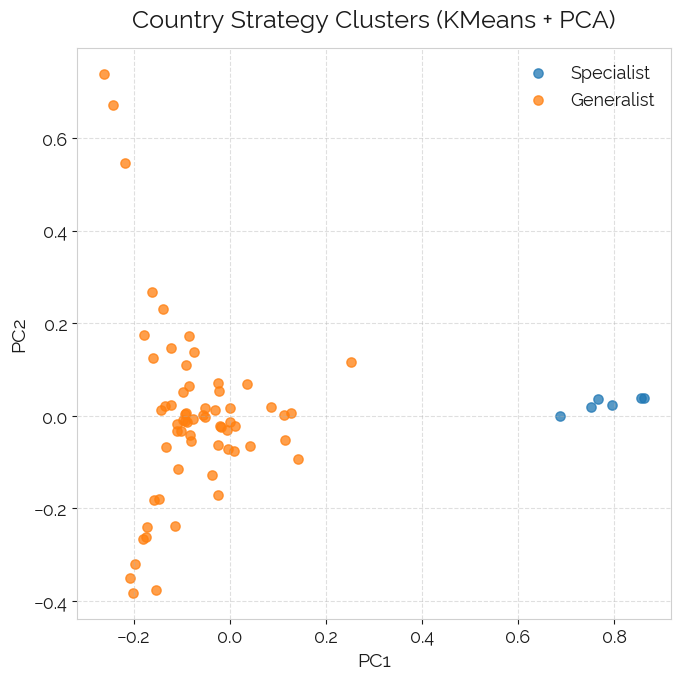

In [9]:
plt.figure(figsize=(7, 7))

for label in ["Specialist", "Generalist"]:
    subset = viz[viz["Cluster_Label"] == label]
    plt.scatter(subset["PC1"], subset["PC2"], label=label, alpha=0.75, s=45)

plt.title("Country Strategy Clusters (KMeans + PCA)", fontsize=18, pad=15)
plt.xlabel("PC1", fontsize=14)
plt.ylabel("PC2", fontsize=14)

plt.grid(linestyle="--", alpha=0.4)
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("chart_kmeans_clusters_square.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
specialists = viz[viz["Cluster_Label"] == "Specialist"]["Country"].head(8).tolist()
generalists = viz[viz["Cluster_Label"] == "Generalist"]["Country"].head(8).tolist()

print("Specialist examples:", specialists)
print("Generalist examples:", generalists)

Specialist examples: ['Bahamas', 'Ethiopia', 'Jamaica', 'Kenya', 'Morocco', 'Trinidad']
Generalist examples: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Belarus', 'Belgium', 'Brazil', 'Bulgaria']
